## Context

This notebook accompanies User Guide section 19 (Severity + FailureCode taxonomy). It enumerates the 29 `FailureCode` entries, classifies each across the three risk tiers (`advisory`, `recommendation`, `action_taking`), and renders the resulting matrix as a heatmap. The final assertion is that every `action_taking` + `FACT_INCORRECT` combination resolves to `CRITICAL` — the rule the testing monograph and Ch 8 hardening pass both turn on.

In [ ]:
# Bootstrap: portable repo-root locator — walks up from CWD looking for
# tutorials/user_guide/notebooks/_shared.py. Works in both the source
# clone (knowlytix/GMS) and the public mirror clone (knowlytix/gmsh).
import sys
import warnings
from pathlib import Path
warnings.filterwarnings('ignore')

_here = Path.cwd().resolve()
for _candidate in [_here, *_here.parents]:
    if (_candidate / 'tutorials' / 'user_guide' / 'notebooks' / '_shared.py').exists():
        if str(_candidate) not in sys.path:
            sys.path.insert(0, str(_candidate))
        break

from tutorials.user_guide.notebooks import _shared as ug
ug.bootstrap_runtime()  # stubs modeva if absent
import torch
DEVICE = ug.DEVICE
print(f'Device: {DEVICE}, CUDA available: {torch.cuda.is_available()}')


### Concept: closed vocabulary, four levels, one promotion rule

`FailureCode` is a closed enum of 29 entries grouped by GMS verification route (semantic, graph, logic, numeric, exactness, agentic, process, recovery, human interaction, system). A novel failure mode is added by extending the enum, not by passing free-text — that is what makes cross-run aggregation byte-stable.

`SeverityLevel` is a four-level scale: `LOW`, `MODERATE`, `HIGH`, `CRITICAL`. `SeverityClassifier` maps each `FailureCode` to a base level via `CODE_SEVERITY_MAP`, then applies a tier-driven promotion: when the failure's base level is in `_TIER_ESCALATION[risk_tier]`, the level is escalated by one step. The default table promotes `MODERATE` and `HIGH` for `action_taking`, and only `MODERATE` for `recommendation`. The consequence is the rule that matters in production: an `action_taking` tier `FACT_INCORRECT` is **CRITICAL**, not HIGH. An advisory tier can absorb a wrong number; a recommendation tier should re-derive; an action-taking tier that acts on a wrong number causes irrecoverable damage. The promotion encodes that asymmetry in one place.

The classifier also computes three `[0, 1]` dimension scores — `impact`, `recoverability`, `detectability` — and a weighted `composite_score`. When the composite passes `_MODULATION_THRESHOLD = 0.85` the level is promoted one further step, capped at CRITICAL.

In [ ]:
# Enumerate the FailureCode taxonomy
from knowlytix.harness.testing.failures import (
    FailureCode, FailureSeverity, FailureAttribution,
)
from knowlytix.harness.testing.severity import (
    SeverityClassifier, SeverityLevel,
    CODE_SEVERITY_MAP,
)

codes = list(FailureCode)
print(f'FailureCode entries: {len(codes)}')
for c in codes[:6]:
    base = CODE_SEVERITY_MAP.get(c, SeverityLevel.LOW)
    print(f'  {c.value:35s} base={base.value}')
print('  ...')


In [3]:
# Build the FailureCode x risk_tier severity matrix
import numpy as np

classifier = SeverityClassifier()
tiers = ['advisory', 'recommendation', 'action_taking']
level_to_int = {
    SeverityLevel.LOW: 0,
    SeverityLevel.MODERATE: 1,
    SeverityLevel.HIGH: 2,
    SeverityLevel.CRITICAL: 3,
}
matrix = np.zeros((len(codes), len(tiers)), dtype=int)
for i, code in enumerate(codes):
    for j, tier in enumerate(tiers):
        a = classifier.classify_code(code, risk_tier=tier)
        matrix[i, j] = level_to_int[a.level]

# Show that action_taking + fact_incorrect -> CRITICAL
fi_idx = codes.index(FailureCode.FACT_INCORRECT)
for j, tier in enumerate(tiers):
    lv = SeverityLevel(
        list(level_to_int)[matrix[fi_idx, j]].value
    )
    print(f'  FACT_INCORRECT in {tier:15s} -> {lv.value}')


  FACT_INCORRECT in advisory        -> high
  FACT_INCORRECT in recommendation  -> high
  FACT_INCORRECT in action_taking   -> critical


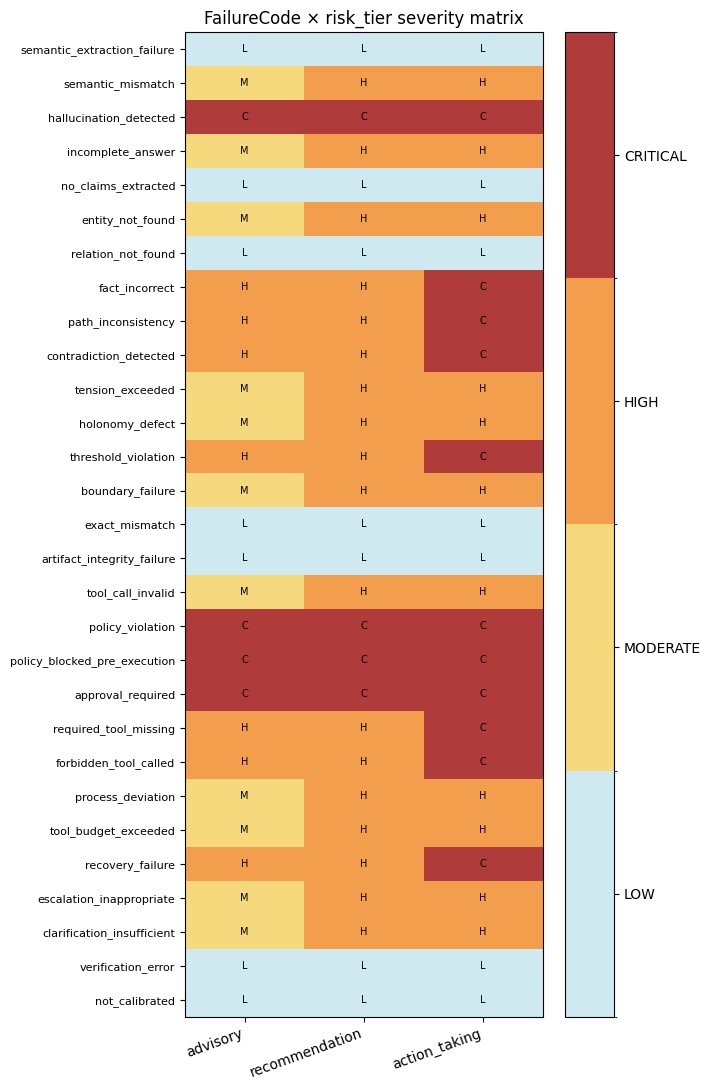

In [4]:
# Visualization: matplotlib imshow heatmap
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm

level_colors = ['#cfe9f1',  # LOW
                '#f6d97c',  # MODERATE
                '#f29e4c',  # HIGH
                '#b03b3b']  # CRITICAL
cmap = ListedColormap(level_colors)
norm = BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 3.5], cmap.N)

fig, ax = plt.subplots(figsize=(7, 11))
im = ax.imshow(matrix, cmap=cmap, norm=norm, aspect='auto')
ax.set_xticks(range(len(tiers)))
ax.set_xticklabels(tiers, rotation=20, ha='right')
ax.set_yticks(range(len(codes)))
ax.set_yticklabels([c.value for c in codes], fontsize=8)
ax.set_title('FailureCode \u00d7 risk_tier severity matrix')
for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        lv = list(level_to_int)[matrix[i, j]]
        ax.text(j, i, lv.value[0].upper(),
                ha='center', va='center', fontsize=7,
                color='black')
cbar = fig.colorbar(im, ax=ax, ticks=[0, 1, 2, 3])
cbar.ax.set_yticklabels(['LOW', 'MODERATE', 'HIGH', 'CRITICAL'])
fig.tight_layout()
plt.show()


In [5]:
# Walk through the dimension scores for FACT_INCORRECT across tiers
for tier in tiers:
    a = classifier.classify_code(
        FailureCode.FACT_INCORRECT, risk_tier=tier,
    )
    print(
        f'  {tier:15s} level={a.level.value:9s} '
        f'composite={a.composite_score:0.3f} '
        f'impact={a.impact_score:0.2f} '
        f'recov={a.recoverability_score:0.2f} '
        f'detect={a.detectability_score:0.2f}'
    )


  advisory        level=high      composite=0.600 impact=0.67 recov=0.33 detect=0.60
  recommendation  level=high      composite=0.650 impact=0.77 recov=0.33 detect=0.60
  action_taking   level=critical  composite=0.700 impact=0.87 recov=0.33 detect=0.60


In [ ]:
# A FailureAttribution stores the structured record an audit packet quotes

failure = FailureAttribution(
    code=FailureCode.FACT_INCORRECT,
    claim_id='claim_017',
    verifier='GraphVerifier',
    severity=FailureSeverity.ERROR,
    detail='(target_variable, IS, age) - not in store',
    gms_method='score_triple',
    raw_score=1.83,
    suggested_action='Re-run with corrected target variable',
)
assessment = classifier.classify(
    failure, risk_tier='action_taking',
)
failure.severity_assessment = assessment
print('classified:', assessment.level.value)
print('rationale :', assessment.rationale)


### Exercises

1. Construct a `SeverityClassifier` with a custom map that promotes `EXACT_MISMATCH` to `HIGH`. Re-render the heatmap and confirm the row darkens uniformly across all tiers.
2. Pick a `FailureCode` whose base level is `MODERATE`. Build a `FailureAttribution` with `gms_method='tension_energy'` and `raw_score=1.95`. Verify that the recoverability score drops, the composite passes 0.85, and the level is promoted by the geometric modulation rule.
3. Use `classify_all` over a list of 10 mixed failures and call `count_by_level` to produce the per-level histogram a release-gate report would consume.

### What you should now be able to do

- Enumerate the 29 `FailureCode` entries and recall which group each belongs to.
- Map any `(FailureCode, risk_tier)` pair to a `SeverityLevel` via `classify_code`.
- Recognise the `action_taking` promotion rule: any MODERATE or HIGH base level becomes the next step up.
- Read a `FailureAttribution` and identify the `gms_method` that produced the failing signal.

### Cross-references

- USER_GUIDE.md §19 (Severity + FailureCode taxonomy)
- USER_GUIDE.md §17 (Behavioral Contracts) for the same tier names at trajectory level
- `knowlytix/harness/testing/failures.py:FailureCode`, `:FailureAttribution`
- `knowlytix/harness/testing/severity.py:SeverityClassifier`, `:CODE_SEVERITY_MAP`, `:_TIER_ESCALATION`
- `gmsh_testing_ext/chapters/appendix_c.tex`

In [7]:
# Final assertion: every action_taking + FACT_INCORRECT
# resolves to CRITICAL. There is exactly one combination
# (the tier is not parameterised below the call), so we
# verify both the cell value in the matrix and a fresh
# call to the classifier.
fi_idx = codes.index(FailureCode.FACT_INCORRECT)
at_idx = tiers.index('action_taking')
assert matrix[fi_idx, at_idx] == level_to_int[SeverityLevel.CRITICAL], (
    f'matrix says FACT_INCORRECT @ action_taking = '
    f'{matrix[fi_idx, at_idx]}, expected '
    f'{level_to_int[SeverityLevel.CRITICAL]}'
)
fresh = classifier.classify_code(
    FailureCode.FACT_INCORRECT, risk_tier='action_taking',
)
assert fresh.level == SeverityLevel.CRITICAL, (
    f'expected CRITICAL, got {fresh.level}'
)
print('OK: action_taking + FACT_INCORRECT -> CRITICAL.')


OK: action_taking + FACT_INCORRECT -> CRITICAL.
